# Lab 2 - Probability and Statistics

Sultan Akinola Atanda (9114837)

Part A: classify emails as spam or not spam using Gaussian and Multinomial Naive Bayes, and compare the two.

Part B: remove outliers from the NYC Airbnb dataset based on price per night.

### Importing libraries

These are all the libraries I need for both parts: numpy and pandas to work with the data, Plotly for the charts, and scikit-learn for splitting the data, building the two Naive Bayes models and scoring them.

In [3]:
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report, roc_curve, roc_auc_score)

I'm using Plotly for the charts because they're interactive, so hovering over a bar or a point shows the exact value.

## Part A - Spam classification

### Loading the data

Loading the spam dataset and looking at the first five rows.

In [4]:
spam = pd.read_csv("Lab2_dataset.csv")
spam.head()

,Unnamed: 0,label,text,label_num
0,605,ham,Subject: enron methanol ; meter # : 988291\nth...,0
1,2349,ham,"Subject: hpl nom for january 9 , 2001\n( see a...",0
2,3624,ham,"Subject: neon retreat\nho ho ho , we ' re arou...",0
3,4685,spam,"Subject: photoshop , windows , office . cheap ...",1
4,2030,ham,Subject: re : indian springs\nthis deal is to ...,0


Each row is one email. `text` is the email itself, `label` is ham or spam, and `label_num` is the same label as a number (0 = ham, 1 = spam), which is what the models will predict. The first column looks like an index left over from an earlier file.

Next I checked the column types and whether anything is missing.

In [5]:
spam.info()

<class 'pandas.DataFrame'>
RangeIndex: 5171 entries, 0 to 5170
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   Unnamed: 0  5171 non-null   int64
 1   label       5171 non-null   str  
 2   text        5171 non-null   str  
 3   label_num   5171 non-null   int64
dtypes: int64(2), str(2)
memory usage: 5.3 MB


There are 5,171 emails and no missing values in any column, so nothing needs to be filled in.

The first column is just an old index so I dropped it. While scrolling through the emails I noticed some of them were repeated, so I checked for duplicates.

In [6]:
spam = spam.drop(columns="Unnamed: 0")
print("duplicate emails:", spam.duplicated("text").sum())

duplicate emails: 178


There are 178 duplicates. If I keep them, the same email could end up in both the training and the test set, and the test score would look better than it actually is.

So I removed the duplicates. Every email also starts with "Subject:", which doesn't help separate the classes, so I took that out as well and then counted how many of each class are left.

In [7]:
spam = spam.drop_duplicates("text").reset_index(drop=True)
spam["text"] = spam["text"].str.replace(r"^Subject:\s*", "", regex=True)
spam["label"].value_counts()

label
ham     3531
spam    1462
Name: count, dtype: int64

After cleaning there are 4,993 emails: 3,531 ham and 1,462 spam.

### Probability behind Naive Bayes

Naive Bayes uses Bayes' theorem to get the probability that an email is spam given the words in it:

$$P(spam \mid words) \propto P(spam) \times \prod_i P(w_i \mid spam)$$

P(spam) is the prior, which is just the fraction of spam emails. The "naive" part is that it assumes every word is independent of the others once we know the class. It calculates this for both classes and picks the one with the higher probability.

The priors for this dataset:

In [8]:
spam["label"].value_counts(normalize=True)

label
ham     0.70719
spam    0.29281
Name: proportion, dtype: float64

So P(ham) is about 0.707 and P(spam) is about 0.293. These are the starting probabilities the models use before they look at any words.

A quick bar chart of the class balance:

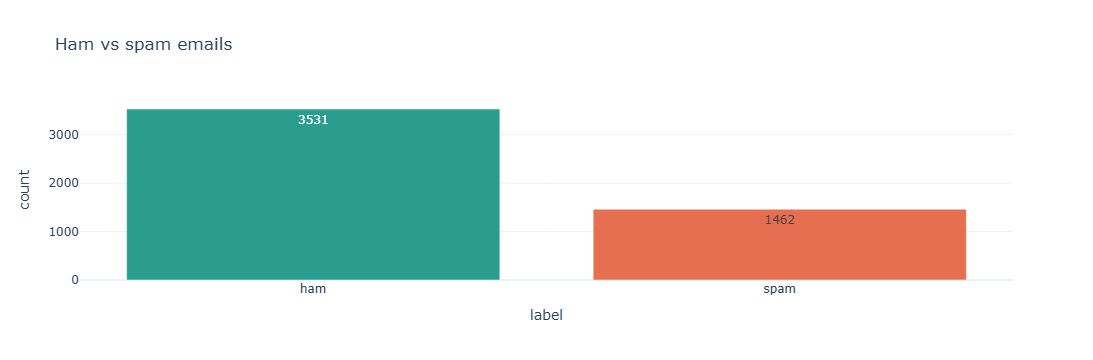

In [9]:
counts = spam["label"].value_counts().reset_index()
fig = px.bar(counts, x="label", y="count", color="label", text="count",
             color_discrete_map={"ham": "#2a9d8f", "spam": "#e76f51"},
             title="Ham vs spam emails", template="plotly_white")
fig.update_layout(showlegend=False)
fig.show()

About 71% ham and 29% spam. This means a model that predicts "ham" for everything would already get around 71% accuracy, so I'm also looking at precision, recall and F1 for the spam class instead of only accuracy.

### Train/test split

80% train, 20% test. I used `stratify` so both sets keep the same spam ratio, and `random_state=42` so the split is the same every time the notebook runs.

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    spam["text"], spam["label_num"], test_size=0.2, random_state=42, stratify=spam["label_num"]
)

print("train:", len(X_train), " test:", len(X_test))
print("spam ratio in train:", round(y_train.mean(), 3), " in test:", round(y_test.mean(), 3))

train: 3994  test: 999
spam ratio in train: 0.293  in test: 0.293


The training set has 3,994 emails and the test set has 999, and both are 29.3% spam, so the stratify worked.

### Turning the text into numbers

The models can't use raw text, so I used CountVectorizer to count how many times each word appears in each email (bag of words). I removed English stop words, only kept words made of letters, and ignored any word that appears in fewer than 3 emails. The vectorizer is fit on the training emails only so nothing from the test set leaks in.

In [11]:
cv = CountVectorizer(stop_words="english", token_pattern=r"(?u)\b[a-z]{2,}\b", min_df=3)
train_counts = cv.fit_transform(X_train)
test_counts = cv.transform(X_test)

train_counts.shape

(3994, 10488)

So each email is now a row of 10,488 word counts. MultinomialNB can use these counts directly, since it's made for this kind of data. GaussianNB assumes every feature follows a normal distribution (it learns a mean and variance for each word in each class) and it needs a dense array, so I convert the matrix with `.toarray()` for it.

### Training the models

Now I train both models on the same training data and use them to predict the test emails. GaussianNB gets the dense version of the counts.

In [12]:
gnb = GaussianNB()
gnb.fit(train_counts.toarray(), y_train)

mnb = MultinomialNB()
mnb.fit(train_counts, y_train)

gnb_pred = gnb.predict(test_counts.toarray())
mnb_pred = mnb.predict(test_counts)

Both models are trained and have predictions for all 999 test emails. GaussianNB is the slower of the two because it works on the full dense array instead of the sparse one.

First I printed the classification report for each model, which shows precision, recall and F1 for both classes.

In [13]:
print("GaussianNB")
print(classification_report(y_test, gnb_pred, target_names=["ham", "spam"], digits=3))
print("MultinomialNB")
print(classification_report(y_test, mnb_pred, target_names=["ham", "spam"], digits=3))

GaussianNB
              precision    recall  f1-score   support

         ham      0.937     0.986     0.961       706
        spam      0.961     0.840     0.896       293

    accuracy                          0.943       999
   macro avg      0.949     0.913     0.928       999
weighted avg      0.944     0.943     0.942       999

MultinomialNB
              precision    recall  f1-score   support

         ham      0.994     0.955     0.974       706
        spam      0.900     0.986     0.941       293

    accuracy                          0.964       999
   macro avg      0.947     0.971     0.958       999
weighted avg      0.967     0.964     0.964       999



Both have good accuracy, but they behave differently on spam. GaussianNB has higher spam precision (0.961) but much lower spam recall (0.840). MultinomialNB catches almost all the spam (recall 0.986) but with lower precision (0.900).

To compare them side by side, I put the main scores for the spam class into one table.

In [14]:
results = pd.DataFrame({
    "accuracy": [accuracy_score(y_test, gnb_pred), accuracy_score(y_test, mnb_pred)],
    "precision": [precision_score(y_test, gnb_pred), precision_score(y_test, mnb_pred)],
    "recall": [recall_score(y_test, gnb_pred), recall_score(y_test, mnb_pred)],
    "f1": [f1_score(y_test, gnb_pred), f1_score(y_test, mnb_pred)],
}, index=["GaussianNB", "MultinomialNB"])

results.round(4)

,accuracy,precision,recall,f1
GaussianNB,0.9429,0.9609,0.8396,0.8962
MultinomialNB,0.9640,0.9003,0.9863,0.9414


MultinomialNB is higher on accuracy, recall and F1. GaussianNB only wins on precision.

The same scores as a grouped bar chart:

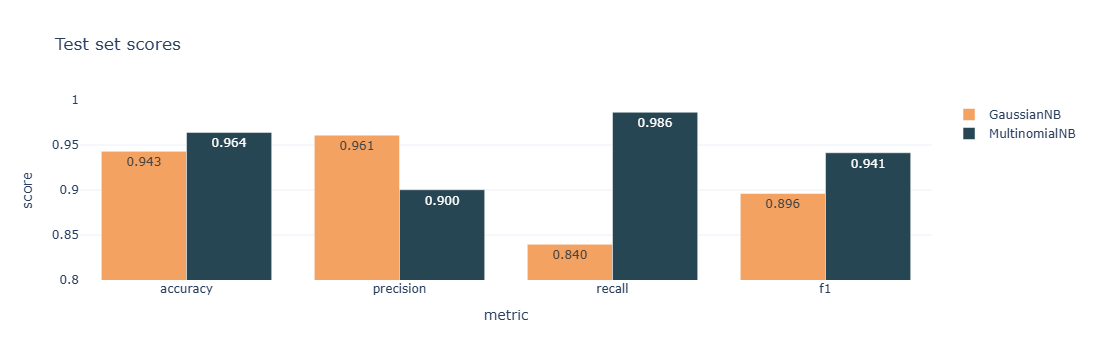

In [15]:
plot_df = results.reset_index().melt(id_vars="index", var_name="metric", value_name="score")
fig = px.bar(plot_df, x="metric", y="score", color="index", barmode="group", text_auto=".3f",
             color_discrete_map={"GaussianNB": "#f4a261", "MultinomialNB": "#264653"},
             title="Test set scores", template="plotly_white")
fig.update_yaxes(range=[0.8, 1])
fig.update_layout(legend_title_text="")
fig.show()

The biggest gap is in recall (about 0.15), which is why Multinomial's F1 is a lot higher even though Gaussian has the better precision.

Confusion matrices show exactly where each model makes its mistakes.

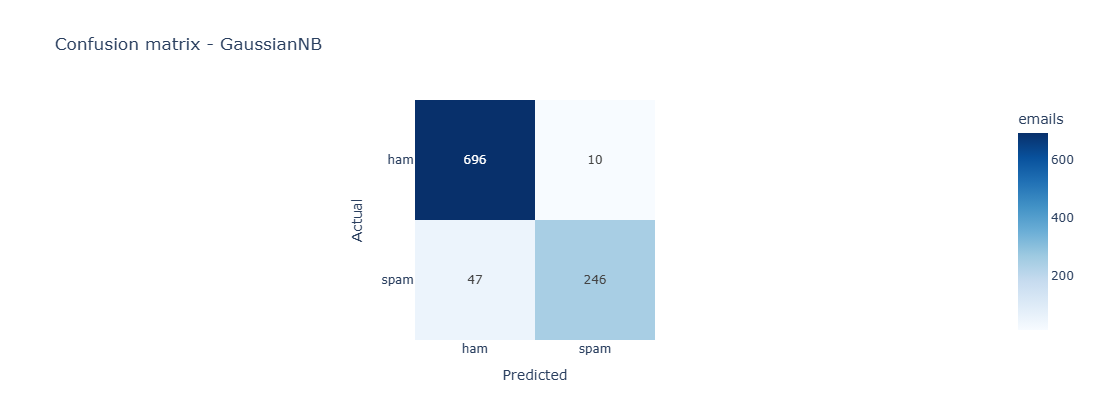

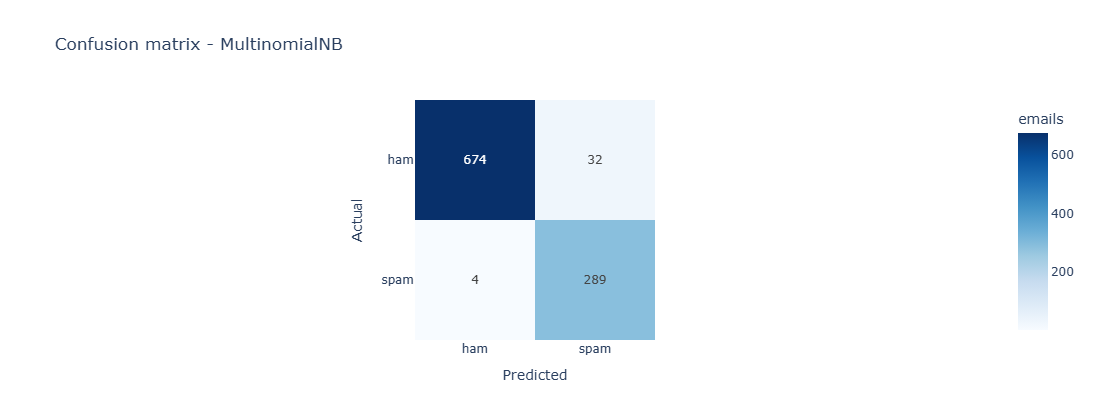

In [16]:
for name, pred in [("GaussianNB", gnb_pred), ("MultinomialNB", mnb_pred)]:
    cm = confusion_matrix(y_test, pred)
    fig = px.imshow(cm, text_auto=True, x=["ham", "spam"], y=["ham", "spam"],
                    color_continuous_scale="Blues", title=f"Confusion matrix - {name}",
                    labels=dict(x="Predicted", y="Actual", color="emails"))
    fig.update_layout(width=450, height=420)
    fig.show()

GaussianNB only flagged 10 ham emails as spam, but it missed 47 spam emails (predicted them as ham). MultinomialNB is the opposite: it only missed 4 spam emails but sent 32 ham emails to spam. In total that's 57 mistakes for Gaussian and 36 for Multinomial.

### ROC curve

The ROC curve checks how well each model's predicted probabilities separate spam from ham at every possible threshold, not just 0.5. A higher AUC is better, and 0.5 would be the same as random guessing.

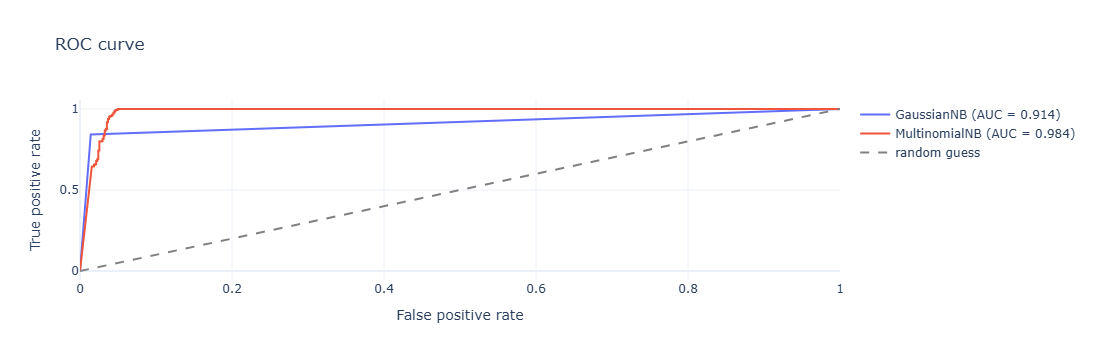

In [17]:
gnb_prob = gnb.predict_proba(test_counts.toarray())[:, 1]
mnb_prob = mnb.predict_proba(test_counts)[:, 1]

fig = go.Figure()
for name, prob in [("GaussianNB", gnb_prob), ("MultinomialNB", mnb_prob)]:
    fpr, tpr, _ = roc_curve(y_test, prob)
    auc = roc_auc_score(y_test, prob)
    fig.add_trace(go.Scatter(x=fpr, y=tpr, mode="lines", name=f"{name} (AUC = {auc:.3f})"))
fig.add_trace(go.Scatter(x=[0, 1], y=[0, 1], mode="lines", line=dict(dash="dash", color="grey"), name="random guess"))
fig.update_layout(title="ROC curve", xaxis_title="False positive rate", yaxis_title="True positive rate",
                  template="plotly_white")
fig.show()

MultinomialNB has an AUC of 0.984 compared to 0.914 for GaussianNB. When I looked at GaussianNB's probabilities, every single one in the test set was below 0.001 or above 0.999. It multiplies thousands of very narrow normal curves together, so it's always extremely confident and can't really rank the emails, which is why its curve is basically one corner point.

### Cross validation

One split could just be lucky, so I also ran 5-fold cross validation on the whole dataset. I was curious whether the number of words used changes the result, so I tried keeping only the 500, 1000, 3000 and 5000 most common words, and then all of them.

In [18]:
to_dense = FunctionTransformer(lambda x: x.toarray(), accept_sparse=True)
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_rows = []
for n_words in [500, 1000, 3000, 5000, None]:
    vec = CountVectorizer(stop_words="english", token_pattern=r"(?u)\b[a-z]{2,}\b", min_df=3, max_features=n_words)
    gnb_f1 = cross_val_score(make_pipeline(vec, to_dense, GaussianNB()), spam["text"], spam["label_num"], cv=folds, scoring="f1")
    mnb_f1 = cross_val_score(make_pipeline(vec, MultinomialNB()), spam["text"], spam["label_num"], cv=folds, scoring="f1")
    cv_rows.append([str(n_words or "all"), gnb_f1.mean(), mnb_f1.mean()])

cv_results = pd.DataFrame(cv_rows, columns=["vocab size", "GaussianNB", "MultinomialNB"])
cv_results.round(4)

,vocab size,GaussianNB,MultinomialNB
0,500,0.8838,0.8638
1,1000,0.9055,0.8844
2,3000,0.9339,0.9196
3,5000,0.9406,0.9305
4,all,0.9085,0.9483


The table shows the average F1 across the 5 folds. MultinomialNB's best is 0.948 using all the words, while GaussianNB's best is 0.940 with 5000 words.

Plotting the same results makes the pattern easier to see.

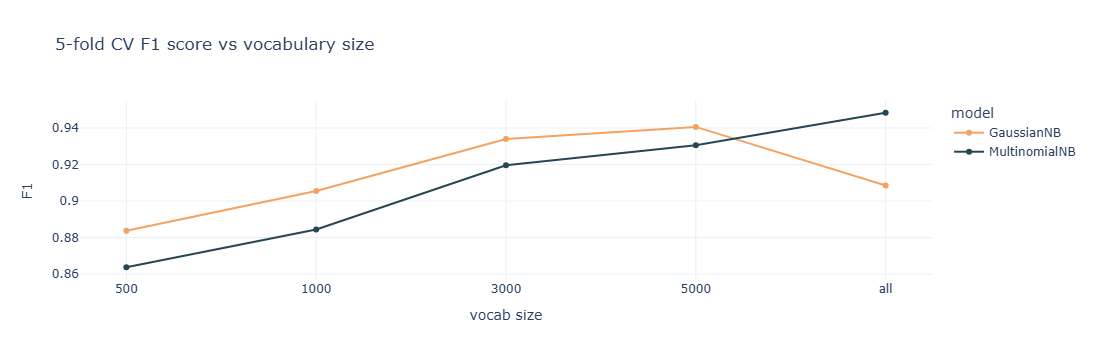

In [19]:
fig = px.line(cv_results.melt(id_vars="vocab size", var_name="model", value_name="F1"),
              x="vocab size", y="F1", color="model", markers=True,
              color_discrete_map={"GaussianNB": "#f4a261", "MultinomialNB": "#264653"},
              title="5-fold CV F1 score vs vocabulary size", template="plotly_white")
fig.show()

This was not what I expected. With a smaller vocabulary GaussianNB is actually a bit better than MultinomialNB. But when all the words are used, MultinomialNB gets its best score (0.948) and GaussianNB drops to 0.909. I think the reason is that most words are 0 in almost every email, so GaussianNB estimates a tiny variance for them. When one of those rare words does show up, the normal curve gives it an extreme probability that takes over the whole prediction. MultinomialNB is made for counts, so having more words only helps it.

### Which model performs better?

MultinomialNB performs better. On the test set it beat GaussianNB on accuracy (0.964 vs 0.943), recall (0.986 vs 0.840), F1 (0.941 vs 0.896) and AUC (0.984 vs 0.914). Its best cross validation F1 (0.948 with all the words) was also the highest of anything I tried.

GaussianNB does have higher precision (0.961 vs 0.900), so it sends fewer real emails to the spam folder, but it lets a lot more spam through and its F1 is much lower. It also makes sense that Multinomial wins, because word counts aren't normally distributed: they're mostly zeros, never negative and very skewed.

### Words the model relies on

For each word, MultinomialNB stores log P(word | spam) and log P(word | ham). Subtracting them shows which words push an email towards spam (positive) or ham (negative).

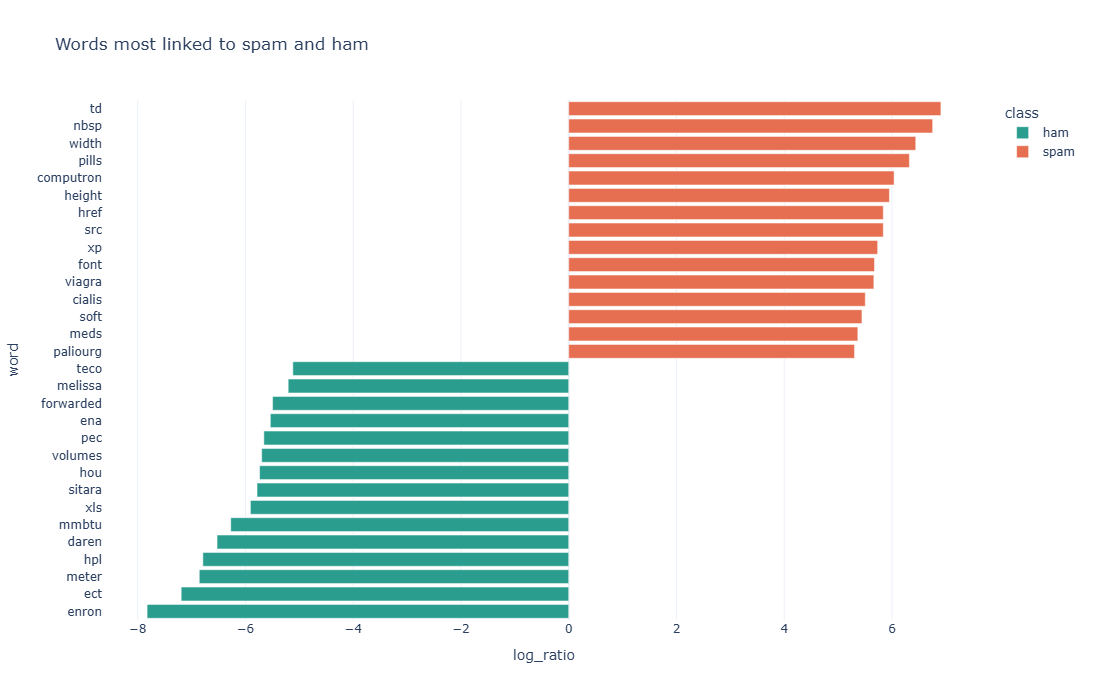

In [20]:
words = cv.get_feature_names_out()
log_ratio = mnb.feature_log_prob_[1] - mnb.feature_log_prob_[0]

top_words = pd.DataFrame({"word": words, "log_ratio": log_ratio}).sort_values("log_ratio")
top_words = pd.concat([top_words.head(15), top_words.tail(15)])
top_words["class"] = np.where(top_words["log_ratio"] > 0, "spam", "ham")

fig = px.bar(top_words, x="log_ratio", y="word", color="class", orientation="h", height=700,
             color_discrete_map={"ham": "#2a9d8f", "spam": "#e76f51"},
             title="Words most linked to spam and ham", template="plotly_white")
fig.show()

The spam side has a lot of HTML words (td, nbsp, width, href, src), which probably come from image-heavy advertising emails, plus words like pills, viagra and meds. The ham side is mostly Enron-specific: enron, ect, hpl, meter, mmbtu, and daren (one of the employees). So part of what the model learned is "does this look like an Enron work email". It would probably not work as well on another company's emails without retraining.

### Predictions on test data

5 ham and 5 spam emails picked at random from the test set, with both models' predictions and MultinomialNB's probability of spam:

In [21]:
sample = pd.concat([X_test[y_test == 0].sample(5, random_state=3),
                    X_test[y_test == 1].sample(5, random_state=3)])
sample_counts = cv.transform(sample)

preds = pd.DataFrame({
    "email": sample.str.replace(r"\s+", " ", regex=True).str[:60] + "...",
    "actual": y_test[sample.index].map({0: "ham", 1: "spam"}),
    "gaussian": gnb.predict(sample_counts.toarray()),
    "multinomial": mnb.predict(sample_counts),
    "P(spam) multinomial": mnb.predict_proba(sample_counts)[:, 1].round(3),
})
preds[["gaussian", "multinomial"]] = preds[["gaussian", "multinomial"]].replace({0: "ham", 1: "spam"})
preds.reset_index(drop=True)

,email,actual,gaussian,multinomial,P(spam) multinomial
0,txu nom . s for 10 / 10 / 00 attached are txu ...,ham,ham,ham,0.000
1,aol instant messenger confirmation thank you f...,ham,ham,spam,1.000
2,"re : spinnaker exploration company , l . l . c...",ham,ham,ham,0.000
3,aep _ hpl transition issues attached is an upd...,ham,ham,ham,0.000
4,shell meter 1581 this meter is coming back up ...,ham,ham,ham,0.000
5,fw : re : he rbv i agr a see the . htm attachm...,spam,ham,ham,0.090
6,"kwbt bio - tech signs letter of intent , gcm a...",spam,spam,spam,1.000
7,"re : your account # bj 535 hi again , i sent a...",spam,spam,spam,1.000
8,"so , it ' s me , varenukha sorry for taking so...",spam,ham,spam,0.795
9,nebenarbeit als gehilfe ! ( ref : 239 ) sehr g...,spam,spam,spam,1.000


Most of them are right. MultinomialNB marked the AOL Instant Messenger confirmation as spam even though it's labelled ham, which is understandable since it reads a lot like a marketing email. Both models missed the first spam email, and GaussianNB also missed the one starting with "so, it's me", which MultinomialNB caught.

I also wrote a few messages of my own to see what happens. Two are obviously spam and two look like the Enron work emails.

In [22]:
my_emails = [
    "Congratulations! You have won a free prize, click here to claim your cash now",
    "Please review the attached gas nomination schedule for Monday's meter volumes",
    "Limited time offer: cheap meds online, no prescription needed",
    "Daren, can we meet tomorrow to go over the Q3 pipeline contract?",
]
my_counts = cv.transform(my_emails)

pd.DataFrame({
    "email": my_emails,
    "gaussian": gnb.predict(my_counts.toarray()),
    "multinomial": mnb.predict(my_counts),
    "P(spam) multinomial": mnb.predict_proba(my_counts)[:, 1].round(3),
}).replace({"gaussian": {0: "ham", 1: "spam"}, "multinomial": {0: "ham", 1: "spam"}})

,email,gaussian,multinomial,P(spam) multinomial
0,"Congratulations! You have won a free prize, cl...",ham,spam,1.0
1,Please review the attached gas nomination sche...,ham,ham,0.0
2,"Limited time offer: cheap meds online, no pres...",spam,spam,1.0
3,"Daren, can we meet tomorrow to go over the Q3 ...",ham,ham,0.0


MultinomialNB got all four right. GaussianNB missed the "you have won a free prize" email, which matches its lower recall on the test set.

## Part B - Removing price outliers (NYC Airbnb 2019)

### Loading the data

Loading the Airbnb dataset and checking its size.

In [23]:
airbnb = pd.read_csv("AB_NYC_2019.csv")
print(airbnb.shape)
airbnb.head()

(48895, 16)


,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


There are 48,895 listings and 16 columns. The column I care about is `price`, the price per night. `room_type` and `neighbourhood_group` will be useful later too.

Summary statistics for price:

In [24]:
airbnb["price"].describe()

count    48895.000000
mean       152.720687
std        240.154170
min          0.000000
25%         69.000000
50%        106.000000
75%        175.000000
max      10000.000000
Name: price, dtype: float64

The maximum price is $10,000 a night while 75% of listings are $175 or less. The minimum is $0, and a listing can't really be free, so I'm treating those as data errors instead of outliers.

Removing the $0 listings and then checking the mean, median, standard deviation and skew.

In [25]:
print("listings with a price of 0:", (airbnb["price"] == 0).sum())
airbnb = airbnb[airbnb["price"] > 0].reset_index(drop=True)
price = airbnb["price"]

print("mean:", round(price.mean(), 2))
print("median:", price.median())
print("std:", round(price.std(), 2))
print("skew:", round(price.skew(), 2))

listings with a price of 0: 11
mean: 152.76
median: 106.0
std: 240.17
skew: 19.12


11 listings had a price of 0. After removing them the mean is $152.76 but the median is only $106, and the skew is 19.12. A normal distribution has a skew of 0, so this is extremely skewed to the right.

Histogram of the price to see the shape:

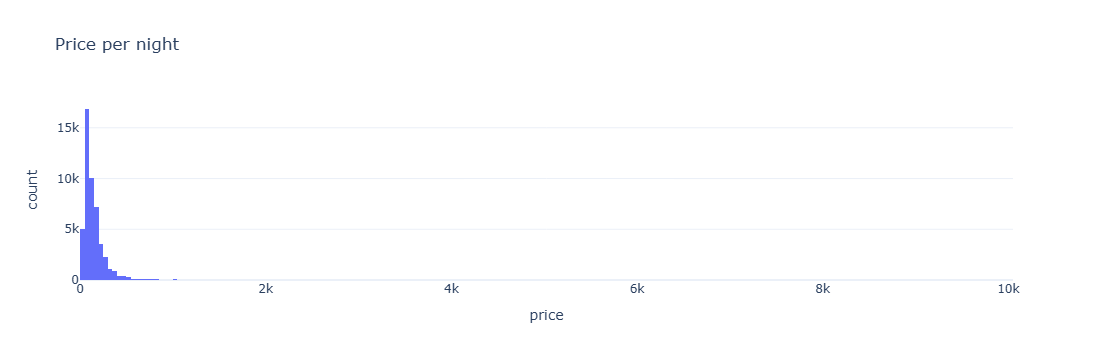

In [26]:
fig = px.histogram(airbnb, x="price", nbins=200, title="Price per night", template="plotly_white")
fig.show()

Almost all the listings are squeezed into the left side, and there is a long thin tail going all the way to $10,000.

Since the data is so skewed, I also looked at the log of the price.

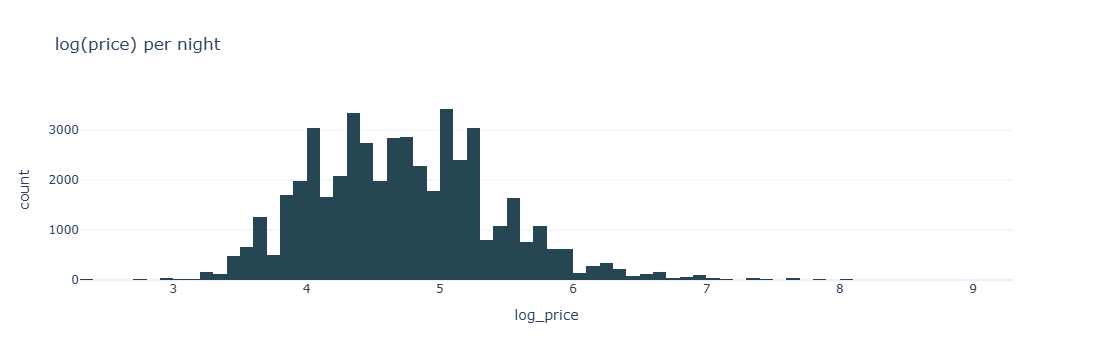

In [27]:
airbnb["log_price"] = np.log(airbnb["price"])
fig = px.histogram(airbnb, x="log_price", nbins=80, title="log(price) per night", template="plotly_white",
                   color_discrete_sequence=["#264653"])
fig.show()

On the log scale the distribution looks a lot closer to a normal curve. I come back to this in method 5.

### 1. Mean and standard deviation

The common rule is that anything more than 3 standard deviations away from the mean is an outlier.

In [28]:
mean, std = price.mean(), price.std()
lower, upper = mean - 3 * std, mean + 3 * std

print(f"lower limit: {lower:.2f}   upper limit: {upper:.2f}")
print("outliers:", ((price < lower) | (price > upper)).sum())

lower limit: -567.76   upper limit: 873.27
outliers: 388


The upper limit is $873, which flags 388 listings. The lower limit is negative, so this rule can never catch a price that is too low.

The bigger issue is that the very expensive listings make the standard deviation huge, which pushes the limit up. To check this I applied the same rule again to whatever was left after each round:

In [29]:
p = price.copy()
for i in range(1, 7):
    limit = p.mean() + 3 * p.std()
    n_out = (p > limit).sum()
    print(f"round {i}: mean = {p.mean():.2f}, std = {p.std():.2f}, upper limit = {limit:.2f}, outliers = {n_out}")
    p = p[p <= limit]

round 1: mean = 152.76, std = 240.17, upper limit = 873.27, outliers = 388
round 2: mean = 138.78, std = 107.55, upper limit = 461.43, outliers = 1031
round 3: mean = 128.70, std = 82.26, upper limit = 375.48, outliers = 844
round 4: mean = 123.55, std = 73.42, upper limit = 343.82, outliers = 654
round 5: mean = 120.26, std = 68.51, upper limit = 325.80, outliers = 117
round 6: mean = 119.71, std = 67.74, upper limit = 322.93, outliers = 124


It keeps finding new outliers every round. Each time the top prices are removed the standard deviation drops a lot, so the limit drops and more listings get flagged. The mean and std are being controlled by the same values I'm trying to remove.

Another quick check: what happens if I remove just the 49 most expensive listings (0.1% of the data)?

In [30]:
trimmed = price.sort_values().iloc[:-49]

print("std:   ", round(price.std(), 2), "->", round(trimmed.std(), 2))
print("mean:  ", round(price.mean(), 2), "->", round(trimmed.mean(), 2))
print("median:", price.median(), "->", trimmed.median())

std:    240.17 -> 155.37
mean:   152.76 -> 147.38
median: 106.0 -> 105.0


The std drops from 240 to 155 and the mean moves by more than $5, while the median only moves by $1. The median and percentiles depend on the order of the values, not on how big the extreme ones are, so they are much more reliable here.

### 2. Median and MAD

MAD is the median of the absolute distances from the median. The modified z-score is

$$z = \frac{0.6745 \, (x - median)}{MAD}$$

and values with |z| > 3.5 are usually treated as outliers.

In [31]:
median = price.median()
mad = (price - median).abs().median()
z = 0.6745 * (price - median) / mad

print("MAD:", mad)
print("upper limit:", round(median + 3.5 * mad / 0.6745, 2))
print("outliers:", (z.abs() > 3.5).sum())

MAD: 46.0
upper limit: 344.7
outliers: 2916


MAD is $46, which gives an upper limit of $344.70 and flags 2,916 listings.

### 3. IQR

Anything below Q1 - 1.5 IQR or above Q3 + 1.5 IQR is an outlier.

In [32]:
q1 = price.quantile(0.25)
q3 = price.quantile(0.75)
iqr = q3 - q1
iqr_lower, iqr_upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr

print("Q1:", q1, " Q3:", q3, " IQR:", iqr)
print("limits:", iqr_lower, "to", iqr_upper)
print("outliers:", ((price < iqr_lower) | (price > iqr_upper)).sum())

Q1: 69.0  Q3: 175.0  IQR: 106.0
limits: -90.0 to 334.0
outliers: 2972


MAD and IQR give almost the same answer: everything above roughly $335-345 is an outlier, which removes about 6% of the listings. Both methods assume the data is spread evenly on both sides of the middle, and price clearly isn't. So a $400 apartment in Manhattan, which is pretty normal, gets removed. The lower limits are negative again.

### 4. Percentiles

Remove everything below the 1st percentile and above the 99th.

In [33]:
p1, p99 = price.quantile([0.01, 0.99])
print("limits:", p1, "to", p99)
print("outliers:", ((price < p1) | (price > p99)).sum())

limits: 30.0 to 799.0
outliers: 867


This one is simple and actually has a lower limit ($30). The downside is that it always removes about 2% of the data, whether those values are unusual or not.

### 5. IQR on log(price)

Since log(price) looked close to normal, I applied the IQR rule to the log and then converted the limits back to dollars with `np.exp`.

In [34]:
lq1, lq3 = airbnb["log_price"].quantile([0.25, 0.75])
liqr = lq3 - lq1
log_lower, log_upper = np.exp(lq1 - 1.5 * liqr), np.exp(lq3 + 1.5 * liqr)

print(f"limits: {log_lower:.2f} to {log_upper:.2f}")
print("outliers:", ((price < log_lower) | (price > log_upper)).sum())

limits: 17.08 to 706.84
outliers: 626


The limits are now $17 to $707. The upper limit is far from the median and the lower one is close, which matches the shape of the data, and it finally catches listings that are suspiciously cheap.

### 6. IQR on log(price) for each room type

All of the methods so far use one limit for every listing. But $500 a night is normal for an entire apartment and very high for a shared room, so I checked how price changes with room type.

In [35]:
airbnb.groupby("room_type")["price"].describe().round(2)

,count,mean,std,min,25%,50%,75%,max
room_type,,,,,,,,
Entire home/apt,25407.0,211.81,284.05,10.0,120.0,160.0,229.0,10000.0
Private room,22319.0,89.81,160.22,10.0,50.0,70.0,95.0,10000.0
Shared room,1158.0,70.25,101.77,10.0,33.0,45.0,75.0,1800.0


Entire homes have a median of $160, private rooms $70 and shared rooms $45. All three still have huge maximums ($10,000, $10,000 and $1,800).

A box plot of price for each room type, on a log scale so the boxes are readable:

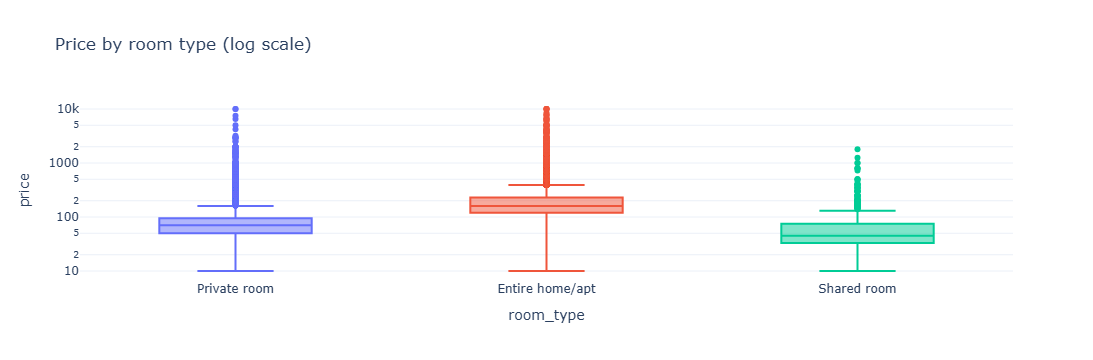

In [36]:
fig = px.box(airbnb, x="room_type", y="price", color="room_type", log_y=True,
             title="Price by room type (log scale)", template="plotly_white")
fig.update_layout(showlegend=False)
fig.show()

The median for an entire home is more than twice the median for a private room, so it makes sense to calculate separate limits for each room type.

Calculating Q1 and Q3 of log(price) for each room type and turning the limits back into dollars:

In [37]:
room_q = airbnb.groupby("room_type")["log_price"].quantile([0.25, 0.75]).unstack()
room_q["iqr"] = room_q[0.75] - room_q[0.25]
room_q["lower"] = np.exp(room_q[0.25] - 1.5 * room_q["iqr"])
room_q["upper"] = np.exp(room_q[0.75] + 1.5 * room_q["iqr"])

room_q[["lower", "upper"]].round(2)

,lower,upper
room_type,,
Entire home/apt,45.52,603.69
Private room,19.09,248.80
Shared room,9.63,256.97


Entire homes are normal between about $46 and $604, private rooms between $19 and $249, and shared rooms up to $257.

Now each listing is compared with the limits for its own room type.

In [38]:
airbnb["lower"] = airbnb["room_type"].map(room_q["lower"])
airbnb["upper"] = airbnb["room_type"].map(room_q["upper"])
airbnb["outlier"] = (airbnb["price"] < airbnb["lower"]) | (airbnb["price"] > airbnb["upper"])

print("outliers:", airbnb["outlier"].sum())

outliers: 1373


This removes 1,373 listings (2.8%). Compared with a single limit for everything, a $300 shared room is now flagged while a $550 entire apartment is kept. I thought about also splitting by borough, but some groups would be too small to get reliable quartiles (Staten Island only has 9 shared rooms), so I kept it to room type.

### Comparing all the methods

To compare the six methods, I put the number removed and the stats of what's left into one table.

In [39]:
methods = {
    "mean +/- 3 std": (price < lower) | (price > upper),
    "median / MAD": z.abs() > 3.5,
    "IQR": (price < iqr_lower) | (price > iqr_upper),
    "1st-99th percentile": (price < p1) | (price > p99),
    "IQR on log price": (price < log_lower) | (price > log_upper),
    "log IQR by room type": airbnb["outlier"],
}

comparison = pd.DataFrame({
    "removed": [m.sum() for m in methods.values()],
    "removed %": [m.mean() * 100 for m in methods.values()],
    "mean after": [price[~m].mean() for m in methods.values()],
    "median after": [price[~m].median() for m in methods.values()],
    "std after": [price[~m].std() for m in methods.values()],
    "skew after": [price[~m].skew() for m in methods.values()],
}, index=list(methods))

comparison.round(2)

,removed,removed %,mean after,median after,std after,skew after
mean +/- 3 std,388,0.79,138.78,105.0,107.55,2.45
median / MAD,2916,5.97,120.27,100.0,68.52,0.94
IQR,2972,6.08,120.00,100.0,68.13,0.92
1st-99th percentile,867,1.77,138.50,105.0,103.69,2.28
IQR on log price,626,1.28,136.20,105.0,99.37,2.06
log IQR by room type,1373,2.81,131.97,100.0,91.03,1.81


The skew after cleaning ranges from 0.92 (IQR) to 2.45 (mean +/- 3 std), and the number of listings removed goes from 388 to 2,972.

Percentage of listings removed by each method:

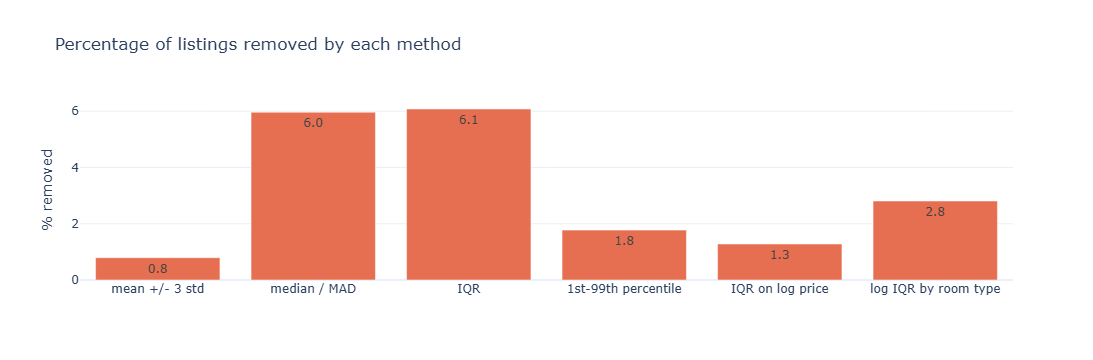

In [40]:
fig = px.bar(comparison.reset_index(), x="index", y="removed %", text_auto=".1f",
             color_discrete_sequence=["#e76f51"],
             title="Percentage of listings removed by each method", template="plotly_white")
fig.update_layout(xaxis_title="", yaxis_title="% removed")
fig.show()

IQR and MAD remove more than twice as much as the room type method, and mean +/- 3 std removes the least.

And how the mean and median change after each method, compared with the original values (dotted lines):

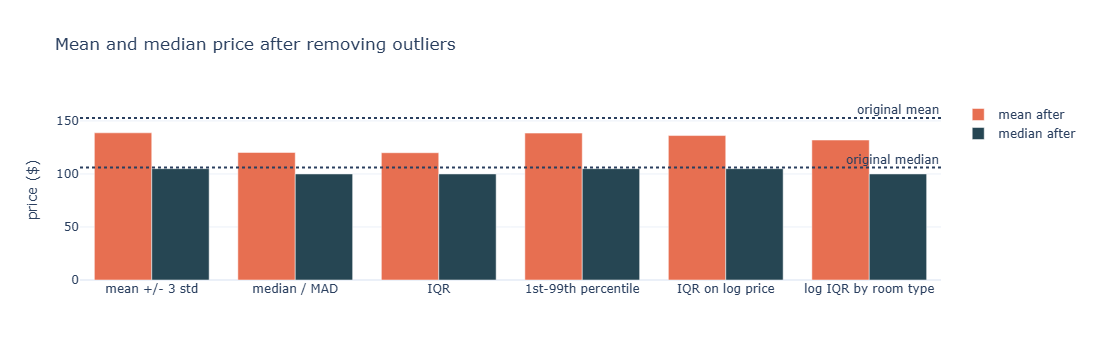

In [41]:
fig = px.bar(comparison.reset_index(), x="index", y=["mean after", "median after"], barmode="group",
             color_discrete_sequence=["#e76f51", "#264653"],
             title="Mean and median price after removing outliers", template="plotly_white")
fig.add_hline(y=price.mean(), line_dash="dot", annotation_text="original mean")
fig.add_hline(y=price.median(), line_dash="dot", annotation_text="original median")
fig.update_layout(xaxis_title="", yaxis_title="price ($)", legend_title_text="")
fig.show()

The original mean ($153) is way above the original median ($106). Every method brings the mean down towards the median, and MAD, IQR and the room type method also lower the median to $100.

Summary of each method:

- **mean +/- 3 std** removes the fewest listings but still leaves a skew of 2.45. It can't catch low prices, and the rounds above showed it isn't stable.
- **MAD and IQR** remove around 6%, the most of any method, because they cut everything above about $335. They end up with the lowest skew, but only because they throw away a lot of normal expensive listings.
- **Percentiles** remove a fixed 2% whether or not those values are unusual.
- **IQR on log price** fits the skewed shape and gives a sensible lower limit.
- **log IQR by room type** is the one I went with. It removes 2.8%, the mean and median end up much closer ($132 vs $100), and each listing is only compared with similar listings.

### Final clean dataset

Keeping only the listings that aren't outliers, dropping the extra columns I added, and checking the new price stats.

In [42]:
clean = airbnb[~airbnb["outlier"]].drop(columns=["log_price", "lower", "upper", "outlier"]).reset_index(drop=True)
removed = airbnb[airbnb["outlier"]]

print("before:", len(airbnb), " after:", len(clean), " removed:", len(removed))
clean["price"].describe().round(2)

before: 48884  after: 47511  removed: 1373


count    47511.00
mean       131.97
std         91.03
min         10.00
25%         68.00
50%        100.00
75%        170.00
max        600.00
Name: price, dtype: float64

47,511 listings are left. The mean is now $131.97 and the median $100, the std went from $240 to $91, and the max is $600.

Comparing the median and max of each room type before and after cleaning:

In [43]:
print("skew before:", round(price.skew(), 2), " after:", round(clean["price"].skew(), 2))

pd.DataFrame({
    "median before": airbnb.groupby("room_type")["price"].median(),
    "median after": clean.groupby("room_type")["price"].median(),
    "max before": airbnb.groupby("room_type")["price"].max(),
    "max after": clean.groupby("room_type")["price"].max(),
})

skew before: 19.12  after: 1.81


,median before,median after,max before,max after
room_type,,,,
Entire home/apt,160.0,160.0,10000,600
Private room,70.0,70.0,10000,246
Shared room,45.0,45.0,1800,250


The median for each room type stayed exactly the same, while the max for entire homes went from $10,000 to $600 and the skew dropped from 19.1 to 1.8. So the cleaning removed the extreme tail without changing what a typical listing costs.

Box plot of the clean prices by room type, on a normal scale this time:

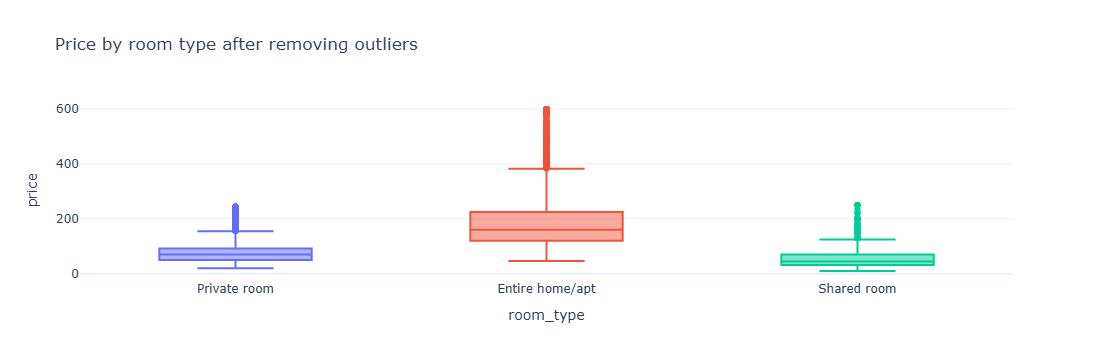

In [44]:
fig = px.box(clean, x="room_type", y="price", color="room_type",
             title="Price by room type after removing outliers", template="plotly_white")
fig.update_layout(showlegend=False)
fig.show()

The boxes are clearly visible now without needing a log scale, and entire homes are still the most expensive with the widest range. The dots above the whiskers are not outliers by my method. Plotly draws its own whiskers using 1.5 IQR on the raw prices of the data it's given, so once the extreme values are gone it recalculates tighter limits on what's left (the same problem as the mean +/- 3 std rounds). The final check at the end compares every listing against the limits I actually used.

Histogram of the clean prices, split by room type:

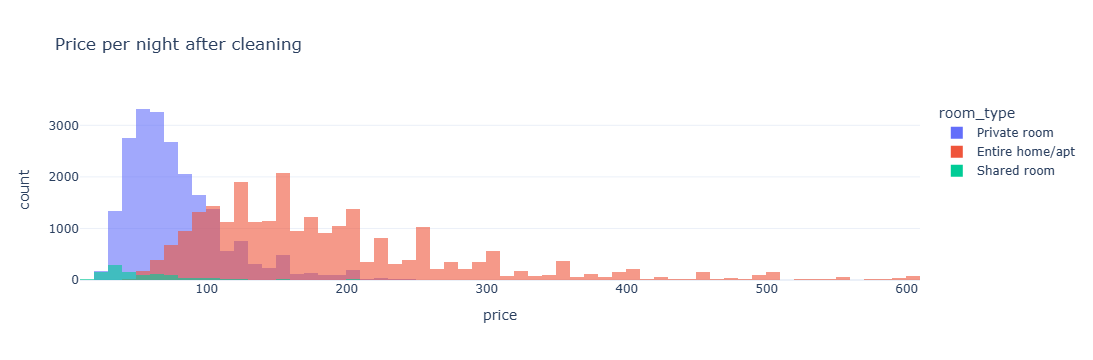

In [45]:
fig = px.histogram(clean, x="price", color="room_type", nbins=60, barmode="overlay", opacity=0.6,
                   title="Price per night after cleaning", template="plotly_white")
fig.show()

The distribution still has a right tail, which is normal for prices, but it now ends at $600 instead of $10,000.

Where are the removed listings? Counting them by borough and by neighbourhood:

In [46]:
print(removed["neighbourhood_group"].value_counts())
print()
print(removed["neighbourhood"].value_counts().head())

neighbourhood_group
Manhattan        982
Brooklyn         292
Queens            72
Bronx             20
Staten Island      7
Name: count, dtype: int64

neighbourhood
Midtown            272
Upper West Side     83
Hell's Kitchen      79
Williamsburg        57
Chelsea             53
Name: count, dtype: int64


Most of them are in Manhattan (982 of 1,373), and Midtown alone has 272.

### Final check

To show the clean data has no outliers left, I plotted every kept listing (violins) against the limits for its room type (dashed lines), together with the listings that were removed (red points). Price is on a log scale so the cheap outliers are visible too.

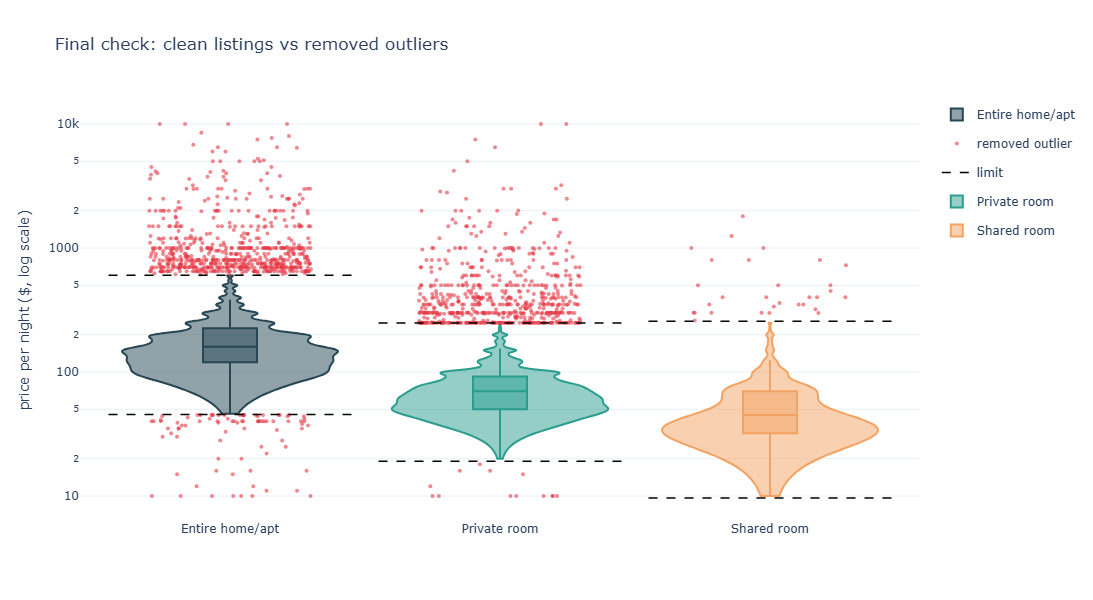

In [47]:
rooms = ["Entire home/apt", "Private room", "Shared room"]
colors = ["#264653", "#2a9d8f", "#f4a261"]
rng = np.random.default_rng(0)

fig = go.Figure()
for i, (room, color) in enumerate(zip(rooms, colors)):
    kept = clean.loc[clean["room_type"] == room, "price"]
    out = removed.loc[removed["room_type"] == room, "price"]

    fig.add_trace(go.Violin(x0=i, y=kept, name=room, line_color=color, width=0.8,
                            points=False, spanmode="hard", box_visible=True))
    fig.add_trace(go.Scatter(x=i + rng.uniform(-0.3, 0.3, len(out)), y=out, mode="markers",
                             marker=dict(color="#e63946", size=4, opacity=0.6),
                             name="removed outlier", legendgroup="removed", showlegend=(i == 0)))
    for limit in ["lower", "upper"]:
        fig.add_trace(go.Scatter(x=[i - 0.45, i + 0.45], y=[room_q.loc[room, limit]] * 2, mode="lines",
                                 line=dict(color="black", dash="dash", width=1.5),
                                 name="limit", legendgroup="limit", showlegend=(i == 0 and limit == "lower")))

fig.update_xaxes(tickvals=[0, 1, 2], ticktext=rooms)
fig.update_yaxes(type="log", title="price per night ($, log scale)")
fig.update_layout(title="Final check: clean listings vs removed outliers", template="plotly_white", height=600)
fig.show()

Every violin starts and ends between its two dashed lines, and all the red points sit outside them. The expensive outliers go up to $10,000, while the cheap ones are mostly entire homes listed under $46.

Checking the same thing with numbers: how many listings in the clean data are below or above the limit for their room type?

In [48]:
outside = (clean["price"] < clean["room_type"].map(room_q["lower"])) | (clean["price"] > clean["room_type"].map(room_q["upper"]))
print("listings outside the limits in the clean data:", outside.sum())
print("listings outside the limits in the removed data:", ((removed["price"] < removed["lower"]) | (removed["price"] > removed["upper"])).sum(), "of", len(removed))

listings outside the limits in the clean data: 0
listings outside the limits in the removed data: 1373 of 1373


None of the 47,511 clean listings are outside their limits, and all 1,373 removed listings are. So the clean dataset is free of outliers based on the method I chose.

### Saving the clean dataset

Saving the clean data to a new CSV file.

In [49]:
clean.to_csv("AB_NYC_2019_clean.csv", index=False)

The file `AB_NYC_2019_clean.csv` is saved in the same folder as this notebook and can be used for any further analysis.

## Conclusion

In Part A, MultinomialNB was the better classifier because its assumptions match word count data, while GaussianNB's normal distribution assumption doesn't fit counts that are mostly zero.

In Part B, the mean and standard deviation turned out to be a poor way to find price outliers because the outliers themselves inflate them. Robust measures like the median, IQR and percentiles worked better, and using the IQR on log(price) separately for each room type gave the most sensible limits. The clean dataset has 47,511 listings and is saved as `AB_NYC_2019_clean.csv`.